# 10 · Multi-Agent Systems: Supervisor  🟠 Advanced

One agent with 30 tools gets confused. Split the work into **specialists** coordinated by a **supervisor**:

```
            ┌────────────┐
  START ──▶ │ supervisor │ ──FINISH──▶ END
            └────────────┘
             ▲   │    │   ▲
             │   ▼    ▼   │
       researcher   mathematician
```
* Each specialist is a full ReAct agent with its own tools and prompt.
* The supervisor uses **structured output** to choose the next worker and give it a task.
* Workers hand control back with `Command(goto="supervisor")`.

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Specialist tools & agents

In [2]:
from langchain_core.tools import tool
from langchain.agents import create_agent

KNOWLEDGE_BASE = {
    "india gdp": "India's nominal GDP in 2025 was about 4.2 trillion USD.",
    "japan gdp": "Japan's nominal GDP in 2025 was about 4.3 trillion USD.",
    "india population": "India's population in 2025 was about 1.46 billion.",
    "japan population": "Japan's population in 2025 was about 123 million.",
}

@tool
def search_knowledge_base(query: str) -> str:
    """Look up economic facts (GDP, population) about countries."""
    q = query.lower()
    hits = [fact for key, fact in KNOWLEDGE_BASE.items() if all(w in q for w in key.split())]
    return "\n".join(hits) or "No facts found. Try a query like '<country> gdp' or '<country> population'."

@tool
def multiply(a: float, b: float) -> float:
    """Multiply a by b."""
    return a * b

@tool
def divide(a: float, b: float) -> float:
    """Divide a by b."""
    return a / b

researcher = create_agent(llm, [search_knowledge_base], name="researcher",
    system_prompt="You are a researcher. Find facts with your tool. Never do calculations. Report facts with numbers.")
mathematician = create_agent(llm, [multiply, divide], name="mathematician",
    system_prompt="You are a mathematician. Use your tools for every calculation. Never look up facts. Show the result clearly.")

## 2. The supervisor

> ℹ️ Workers report back as `HumanMessage`s tagged with their name. Claude requires a conversation to end with a
> user turn, so the supervisor always sees the latest worker report as input.

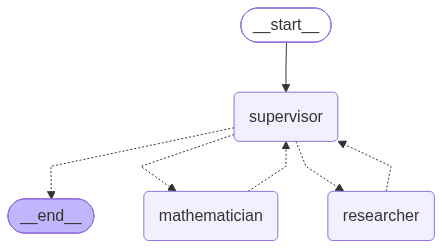

In [3]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.types import Command

class Decision(BaseModel):
    next: Literal["researcher", "mathematician", "FINISH"]
    task: str = Field(description="Clear instruction for the chosen worker incl. any numbers it needs; "
                                  "or, when FINISH, the final answer for the user")

supervisor_llm = llm.with_structured_output(Decision, method="json_schema")

SUPERVISOR_PROMPT = """You manage a team:
- researcher: looks up facts (GDP, population) in a knowledge base
- mathematician: performs calculations
Decide who acts next and give them one focused task. Workers only see what you tell them plus the conversation.
When the user's question is fully answered, choose FINISH and write the final answer in `task`."""

class TeamState(MessagesState):
    task: str
    steps: int

def supervisor(state: TeamState) -> Command[Literal["researcher", "mathematician", "__end__"]]:
    if state.get("steps", 0) >= 6:                       # safety valve
        return Command(goto=END, update={"messages": [AIMessage("Stopping: step limit reached.")]})
    d = supervisor_llm.invoke([SystemMessage(SUPERVISOR_PROMPT)] + state["messages"])
    print(f"🧭 supervisor → {d.next}: {d.task[:120]}")
    if d.next == "FINISH":
        return Command(goto=END, update={"messages": [AIMessage(d.task, name="supervisor")]})
    return Command(goto=d.next, update={"task": d.task, "steps": state.get("steps", 0) + 1})

def make_worker(name, agent):
    def worker(state: TeamState) -> Command[Literal["supervisor"]]:
        result = agent.invoke({"messages": state["messages"] + [HumanMessage(f"Your task: {state['task']}")]})
        report = result["messages"][-1].text
        print(f"   👷 {name}: {report[:150]}")
        return Command(goto="supervisor",
                       update={"messages": [HumanMessage(f"[{name} report] {report}", name=name)]})
    return worker

b = StateGraph(TeamState)
b.add_node("supervisor", supervisor)
b.add_node("researcher", make_worker("researcher", researcher))
b.add_node("mathematician", make_worker("mathematician", mathematician))
b.add_edge(START, "supervisor")
team = b.compile()
show_graph(team)

In [4]:
question = "Which country has the higher GDP per person, India or Japan, and roughly by what factor?"
result = team.invoke({"messages": [("user", question)]})
print("\n✅ FINAL ANSWER:\n", result["messages"][-1].text)

🧭 supervisor → researcher: Look up the most recent nominal GDP (in US dollars) and total population for both India and Japan in the knowledge base.


   👷 researcher: I found all four figures, but I haven't worked out GDP per person or the factor between the two countries. My instructions are to report facts only an


🧭 supervisor → mathematician: Using these 2025 figures (all approximate): India nominal GDP ≈ $4.2 trillion, population ≈ 1.46 billion; Japan nominal 


   👷 mathematician: Japan has the higher GDP per person, about **12 times** India's.

**Working** (2025 figures)

1. **India:** $4.2 trillion ÷ 1.46 billion ≈ $2,876.71, 


🧭 supervisor → FINISH: Japan has the higher GDP per person, roughly 12 times India's.

| Country | Nominal GDP (2025) | Population | GDP per pe

✅ FINAL ANSWER:
 Japan has the higher GDP per person, roughly 12 times India's.

| Country | Nominal GDP (2025) | Population | GDP per person |
|---|---|---|---|
| India | ~$4.2 trillion | ~1.46 billion | ~$2,900 |
| Japan | ~$4.3 trillion | ~123 million | ~$35,000 |

Dividing gives 34,959 ÷ 2,877 ≈ 12.2, so Japan's GDP per person is about 12 times India's.

The two economies are almost the same size. The gap comes from population: India has about 12 times as many people as Japan, so the same output is shared among far more people.

Caveats:
- The inputs are rounded, so read the factor as "about 12." Small changes in the inputs move it between about 11.9 and 12.4.
- These are nominal US-dollar figures. Adjusted for purchasing power, which accounts for lower prices in India, the gap would be much smaller.
- The figures came from an internal kno

## 3. Inspecting the collaboration

In [5]:
print_messages(result["messages"])

===== HUMAN =====
Which country has the higher GDP per person, India or Japan, and roughly by what factor?
===== HUMAN [researcher] =====
[researcher report] I found all four figures, but I haven't worked out GDP per person or the factor between the two countries. My instructions are to report facts only and not do calculations, so that last step is left for you.

| Country | Nominal GDP (USD) | Population | Year |
|---|---|---|---|
| India | about $4.2 trillion | about 1.46 billion | 2025 |
| Japan | about $4.3 trillion | about 123 million | 2025 |

- **Same year:** All four figures are for 2025, so they can be compared directly.
- **Source:** Each figure comes from the knowledge base. It doesn't say where the numbers originally came from (for example, the IMF or World Bank), so I can't give that. If you need it for citations, check the figures against an official source.
- **Rounding:** The values are rounded ("about"), so any per-person figure or factor you work out from them will b

## 4. Other multi-agent architectures

| Architecture | Idea | In LangGraph |
|---|---|---|
| **Supervisor** (this notebook) | central router delegates | `Command(goto=...)` / conditional edges |
| **Hierarchical** | supervisors of supervisor teams | a team graph used as a **subgraph** node |
| **Handoffs / swarm** | agents transfer control to each other via "transfer_to_X" tools | a tool returns `Command(goto="X", graph=Command.PARENT)` |
| **Network** | any agent can call any other | every node returns `Command` to any peer |

Rule of thumb: start with **one** agent; split only when tools/prompts get crowded or you need separate responsibilities.

## ✅ Recap
* Specialists = independent agents with focused tools and prompts.
* Supervisor = structured-output router that writes tasks for workers.
* `Command(goto=..., update=...)` implements handoffs; add a step limit as a safety valve.